# Notebook 7 – Outlier Analysis

# Question 1

# What is an Outlier?

## Step 1: Understand the concept

An outlier is an observation that is significantly different from most other observations in a dataset.

It lies far away from the general pattern of the data.

For example, if most customers have MonthlyCharges between ₹20 and ₹100, a value much higher than this range may be considered an outlier.

An outlier does not always mean that the data is wrong.

It may be:
- A genuine observation
- A data-entry error
- An unusual but valid observation

## Step 2: Demonstrate the concept

In the Telco Customer Churn dataset, we can check:

- MonthlyCharges
- TotalCharges
- Tenure

Some customers may have unusually high charges or tenure values.

These values should be investigated before deciding whether they are outliers that need treatment.


## Step 3: Implementation the concept

In [1]:
# Step 3: Implementation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print("Numerical Features:")
print(numerical_features)

Numerical Features:
['tenure', 'MonthlyCharges', 'TotalCharges']


## Code Explanation

The numerical features are selected because outlier analysis is mainly performed on numerical data.

### Expected Insight

The selected features can now be analyzed to identify unusual observations.

# Question 2

# Why do Outliers occur in a dataset?

## Step 1: Understand the concept

Outliers can occur for different reasons.

Common causes include:

1. Data-entry errors
2. Measurement errors
3. Rare events
4. Genuine extreme values
5. Changes in customer behavior
6. Different business conditions

Therefore, an outlier should not automatically be considered incorrect.

## Step 2: Demonstrate the concept

For example, a customer with very high TotalCharges may be a genuine customer who has:

- Stayed with the company for many months
- Used expensive services
- Paid higher monthly charges

Therefore, the value may be unusual but still valid.


## Step 3: Implementation the concept


In [2]:


print("Maximum values in numerical features:\n")

for column in numerical_features:
    print(f"{column}: {df[column].max()}")

Maximum values in numerical features:

tenure: 72
MonthlyCharges: 118.75
TotalCharges: 8684.8


## Code Explanation

`.max()` finds the highest value in each numerical feature.

Very high values can be investigated further, but a high value alone does not prove that it is an error.

# Question 3

# What are the different types of Outliers?

## Step 1: Understand the concept

There are three common types of outliers.

### 1. Univariate Outlier

An unusual value in a single variable.

Example:
An unusually high MonthlyCharges value.

### 2. Multivariate Outlier

An observation that appears unusual when multiple variables are considered together.

Example:
A customer may have a normal MonthlyCharges value but an unusual combination of MonthlyCharges and TotalCharges.

### 3. Contextual Outlier

A value that is unusual only under a specific condition or context.

Example:
A particular value may be normal for one customer group but unusual for another group.

## Step 2: Demonstrate the concept

In this dataset:

- MonthlyCharges can be checked for univariate outliers.
- Tenure and TotalCharges can be considered together for multivariate analysis.
- Customer groups such as Contract type can provide context for unusual values.

## Step 3: Implementation the concept

In [3]:


print("Dataset Shape:")
print(df.shape)

print("\nNumerical Feature Summary:")
print(df[numerical_features].describe())

Dataset Shape:
(7043, 21)

Numerical Feature Summary:
            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7032.000000
mean     32.371149       64.761692   2283.300441
std      24.559481       30.090047   2266.771362
min       0.000000       18.250000     18.800000
25%       9.000000       35.500000    401.450000
50%      29.000000       70.350000   1397.475000
75%      55.000000       89.850000   3794.737500
max      72.000000      118.750000   8684.800000


# Question 4

# How can we detect Univariate Outliers using the IQR Method?

## Step 1: Understand the concept

IQR stands for Interquartile Range.

IQR is calculated as:

IQR = Q3 - Q1

Where:

Q1 = 25th percentile
Q3 = 75th percentile

Outlier boundaries are:

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Values below the lower bound or above the upper bound are considered potential outliers.

## Step 2: Demonstrate the concept

We will apply the IQR method to:

- Tenure
- MonthlyCharges
- TotalCharges

This helps us identify unusually low or high values in each individual feature.


## Step 3: Implementation the concept

In [4]:


for column in numerical_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\n--- {column} ---")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


--- tenure ---
Q1: 9.0
Q3: 55.0
IQR: 46.0
Lower Bound: -60.0
Upper Bound: 124.0
Number of Outliers: 0

--- MonthlyCharges ---
Q1: 35.5
Q3: 89.85
IQR: 54.349999999999994
Lower Bound: -46.02499999999999
Upper Bound: 171.375
Number of Outliers: 0

--- TotalCharges ---
Q1: 401.45
Q3: 3794.7375
IQR: 3393.2875000000004
Lower Bound: -4688.481250000001
Upper Bound: 8884.66875
Number of Outliers: 0


## Code Explanation

- `quantile(0.25)` calculates Q1.
- `quantile(0.75)` calculates Q3.
- IQR is calculated using Q3 - Q1.
- The lower and upper boundaries are calculated.
- Values outside these boundaries are counted as potential outliers.

### Important

These are only potential outliers. We must investigate them before removing anything.

# Question 5

# How can we detect Outliers using the Z-Score Method?

## Step 1: Understand the concept

Z-Score tells us how far a value is from the mean in terms of standard deviations.

Formula:

Z = (X - Mean) / Standard Deviation

A commonly used rule is:

- Z-Score > +3 → Potential outlier
- Z-Score < -3 → Potential outlier

Therefore:

Absolute Z-Score > 3 → Potential outlier

## Step 2: Demonstrate the concept

We calculate the Z-Score for each numerical feature.

A value with a Z-Score greater than +3 or less than -3 is flagged as a potential outlier.

### Important

Z-Score works best when the data is reasonably suitable for mean and standard deviation based analysis.


## Step 3: Implementation the concept

In [5]:


for column in numerical_features:

    data = df[column].dropna()

    mean = data.mean()
    std = data.std()

    z_scores = (data - mean) / std

    outliers = data[abs(z_scores) > 3]

    print(f"{column}:")
    print("Number of Z-Score Outliers:", len(outliers))
    print()

tenure:
Number of Z-Score Outliers: 0

MonthlyCharges:
Number of Z-Score Outliers: 0

TotalCharges:
Number of Z-Score Outliers: 0



## Code Explanation

- `mean()` calculates the average.
- `std()` calculates standard deviation.
- The Z-Score is calculated for every value.
- `abs(z_scores) > 3` identifies potential outliers.

### Expected Insight

The output shows how many observations are unusually far from the mean.

# Question 6

# How can a Box Plot be used to visually detect Outliers?

## Step 1: Understand the concept

A Box Plot displays the distribution of numerical data.

It shows:

- Median
- Lower Quartile
- Upper Quartile
- Spread of the data
- Potential outliers

Points appearing beyond the whiskers are usually potential outliers.

## Step 2: Demonstrate the concept

We will create Box Plots for:

- Tenure
- MonthlyCharges
- TotalCharges

This allows us to visually identify unusually high or low observations.


## Step 3: Implementation the concept

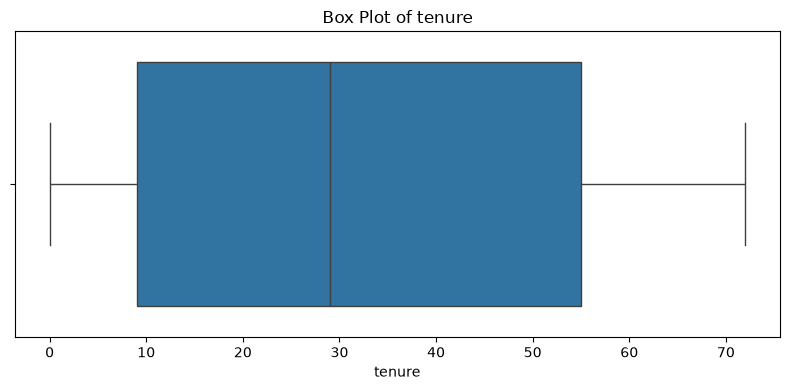

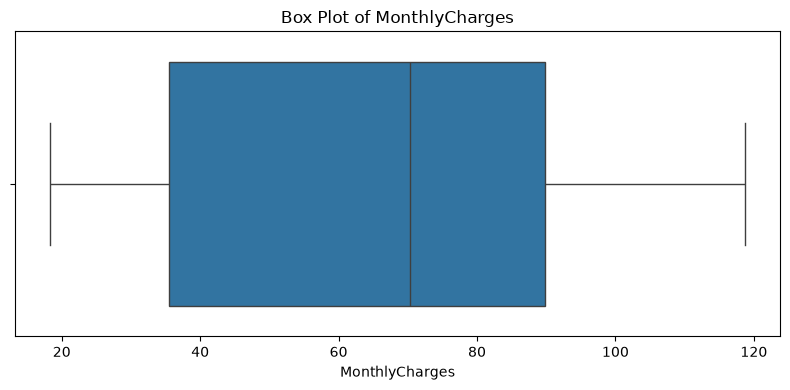

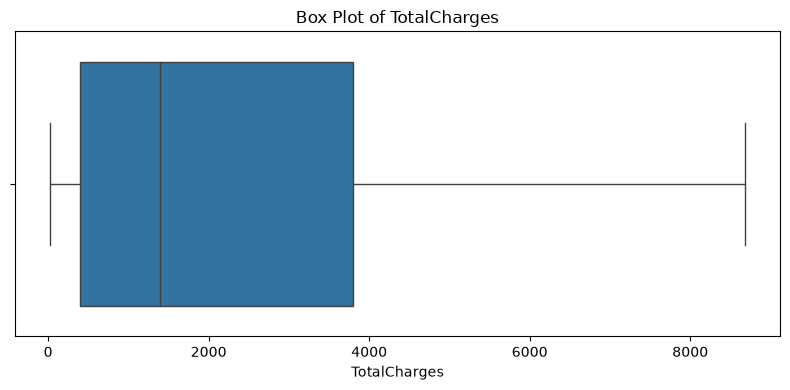

In [6]:


for column in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[column].dropna())

    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

## Code Explanation

`sns.boxplot()` creates a box plot for the selected numerical feature.

Values beyond the whiskers may indicate potential outliers.

### Important

A point outside the whisker is not automatically an error.

It must be investigated before deciding what to do.

# Question 7

# How can a Scatter Plot help detect Multivariate Outliers?

## Step 1: Understand the concept

A multivariate outlier may not look unusual when only one variable is considered.

However, the combination of two variables may reveal an unusual observation.

A Scatter Plot helps us visualize the relationship between two numerical variables and identify observations that are far away from the general pattern.

##  Step 2: Demonstrate the concept

We will compare:

- Tenure
- TotalCharges

Most customers should follow a general relationship between these variables.

Customers that are far away from the main pattern can be investigated as potential multivariate outliers.


## Step 3: Implementation the concept

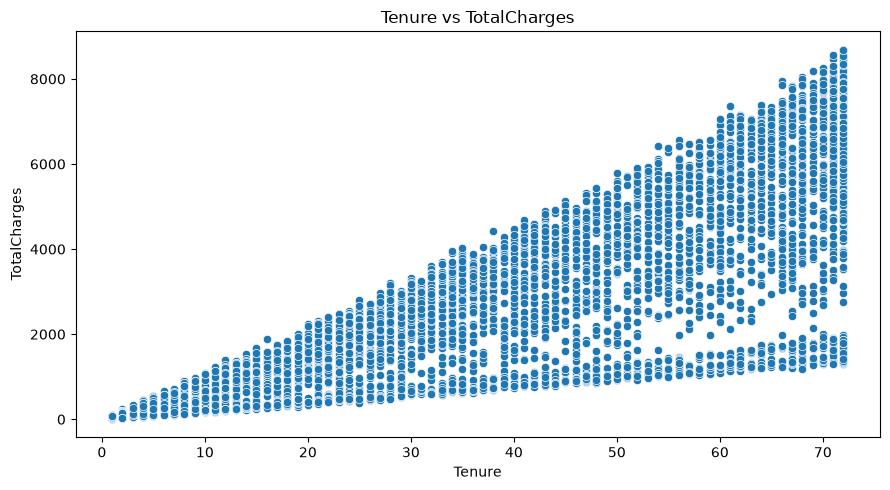

In [7]:


plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="tenure",
    y="TotalCharges"
)

plt.title("Tenure vs TotalCharges")
plt.xlabel("Tenure")
plt.ylabel("TotalCharges")

plt.tight_layout()
plt.show()

## Code Explanation

The Scatter Plot shows the relationship between Tenure and TotalCharges.

Observations that are far away from the general pattern can be investigated as potential multivariate outliers.

### Important

A visually unusual point does not automatically mean that it should be removed.

# Question 8

# For detected outliers, how can we determine whether they are genuine observations, data-entry errors, or unusual but valid observations?

## Step 1: Understand the concept

After detecting an outlier, we should investigate why it occurred.

We should ask:

1. Is it a genuine observation?
2. Is it a data-entry error?
3. Is it an unusual but valid observation?
4. Does it make business sense?
5. Is there evidence that the value is incorrect?

The purpose of outlier analysis is not simply to remove unusual values.

## Step 2: Demonstrate the concept

For example, a customer with high TotalCharges may be a genuine observation if:

- The customer has long tenure.
- The customer has higher MonthlyCharges.
- The values are consistent with the customer's service history.

In this case, the value may be unusual but valid.

If a value is impossible or clearly caused by incorrect data entry, it may require correction or removal.


## Step 3: Implementation the concept

In [8]:


Q1 = df["TotalCharges"].quantile(0.25)
Q3 = df["TotalCharges"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

potential_outliers = df[
    (df["TotalCharges"] < lower_bound) |
    (df["TotalCharges"] > upper_bound)
]

print("Potential TotalCharges Outliers:")
print(
    potential_outliers[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ].head(10)
)

Potential TotalCharges Outliers:
Empty DataFrame
Columns: [customerID, tenure, MonthlyCharges, TotalCharges]
Index: []


## Code Explanation

The code displays potential TotalCharges outliers together with:

- Customer ID
- Tenure
- Monthly Charges
- Total Charges

This additional information helps us investigate whether the unusual value is reasonable.

### Important

The output identifies potential outliers only.

It does not automatically label them as errors.

# Question 9

# Should detected outliers be removed, transformed, or retained?

## Step 1: Understand the concept

An outlier should not automatically be removed.

Possible actions are:

### 1. Remove

Use this when the value is clearly incorrect or caused by a data-entry or measurement error.

### 2. Transform

Use this when the value is genuine but highly skewed and affects analysis or model performance.

Examples:

- Log transformation
- Power transformation

### 3. Retain

Keep the observation when it is genuine and meaningful.

For example, a customer with genuinely high charges should normally be retained.

## Step 2: Demonstrate the concept

Decision process:

Potential Outlier
        ↓
Investigate the observation
        ↓
Is it an error?
   ↙           ↘
 Yes           No
 ↓              ↓
Correct/Remove  Is it valid but extreme?
                 ↙          ↘
               Yes           No
                ↓             ↓
             Retain       Investigate further

If a valid extreme value creates strong skewness, transformation can be considered.



## Step 3: Implementation the concept

In [9]:


outlier_decision = pd.DataFrame({
    "Situation": [
        "Data-entry error",
        "Impossible value",
        "Unusual but valid observation",
        "Valid extreme value causing skewness"
    ],
    "Recommended_Action": [
        "Correct or Remove",
        "Correct or Remove",
        "Retain",
        "Consider Transformation"
    ]
})

print(outlier_decision)

                              Situation       Recommended_Action
0                      Data-entry error        Correct or Remove
1                      Impossible value        Correct or Remove
2         Unusual but valid observation                   Retain
3  Valid extreme value causing skewness  Consider Transformation


## Code Explanation

The decision table documents the appropriate treatment for different types of outliers.

### Key Principle

Outlier treatment should depend on the reason behind the unusual value.

We should never remove an observation only because it is statistically unusual.

# Question 10

# How should we document the reasoning behind an Outlier Treatment decision?

## Step 1: Understand the concept

Every outlier treatment decision should have a clear reason.

The documentation should mention:

- Feature
- Detection method
- Number of potential outliers
- Possible reason
- Whether the observation is valid
- Final decision
- Reason for the decision

## Step 2: Demonstrate the concept

Example:

Feature: TotalCharges

Detection Method: IQR

Observation: High TotalCharges

Investigation:
The customer has long tenure and high MonthlyCharges.

Decision:
Retain the observation.

Reason:
The value is unusual but appears to be a genuine customer observation.



## Step 3: Implementation the concept

In [10]:


outlier_reasoning = pd.DataFrame({
    "Feature": ["TotalCharges"],
    "Detection_Method": ["IQR"],
    "Observation": ["High TotalCharges"],
    "Investigation": [
        "Check Tenure and MonthlyCharges"
    ],
    "Decision": ["Retain if genuine"],
    "Reason": [
        "High charges can be valid for long-term customers"
    ]
})

print("Outlier Treatment Reasoning:")
print(outlier_reasoning)

Outlier Treatment Reasoning:
        Feature Detection_Method        Observation  \
0  TotalCharges              IQR  High TotalCharges   

                     Investigation           Decision  \
0  Check Tenure and MonthlyCharges  Retain if genuine   

                                              Reason  
0  High charges can be valid for long-term customers  
